<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_11_Novelty_and_Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 11 — Novelty and Outlier Detection (Deteksi Kebaruan dan Pencilan)

**Referensi:** *scikit-learn Cookbook, Third Edition* — John Sukup

Notebook ini membahas cara mengenali observasi yang tidak mengikuti pola umum dalam dataset. Contoh menggunakan data sintetis agar anomali yang sengaja dibuat dapat diketahui; dengan demikian, hasil model bisa dievaluasi tanpa mengunduh dataset eksternal.

## Tujuan pembelajaran

- Membedakan **outlier detection** (deteksi pencilan) dan **novelty detection** (deteksi data baru yang tidak biasa).
- Menerapkan Isolation Forest, One-Class SVM, dan Local Outlier Factor (LOF).
- Mengevaluasi hasil deteksi ketika label acuan tersedia.
- Mempertimbangkan tindakan setelah anomali ditemukan.
- Memilih metode sesuai karakteristik data dan kebutuhan operasional.

> Data yang terdeteksi sebagai anomali tidak otomatis merupakan kesalahan. Data tersebut mungkin berasal dari masalah pengukuran, kejadian langka tetapi valid, atau perubahan penting yang perlu diperiksa.

## 11.1 Pengenalan outlier detection dan novelty detection

**Outlier** adalah observasi yang terlihat tidak biasa dibandingkan distribusi data yang dianalisis. **Novelty** adalah observasi baru yang berbeda dari contoh normal yang tersedia saat pelatihan, lalu dinilai ketika data baru masuk.

Penerapannya antara lain pemantauan sensor, penyaringan penipuan, pemeriksaan kualitas, dan pemantauan jaringan. Hasil deteksi merupakan sinyal untuk penyelidikan—bukan bukti bahwa sebuah observasi pasti salah.

Dua konvensi prediksi yang umum di scikit-learn:
- `1` berarti inlier (observasi normal).
- `-1` berarti outlier atau novelty.

Agar metrik mudah dihitung di notebook ini, label acuan dikodekan sebagai `0 = inlier` dan `1 = outlier`.

### Menyiapkan pustaka

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

RANDOM_STATE = 2024

### Membuat dataset sintetis

Kita membuat satu kelompok observasi normal yang padat, kemudian menambahkan titik yang diambil dari area yang lebih luas. Karena outlier dibuat secara sengaja, label sebenarnya juga diketahui. Ide ini berguna untuk menguji model deteksi anomali sebelum digunakan pada data yang tidak memiliki label.

In [ ]:
X_normal, _ = make_blobs(
    n_samples=300,
    centers=[[1.5, 2.0]],
    cluster_std=0.60,
    random_state=RANDOM_STATE
)
rng = np.random.default_rng(RANDOM_STATE)
X_outliers = rng.uniform(low=-6, high=7, size=(25, 2))
X_all = np.vstack([X_normal, X_outliers])
y_true = np.r_[np.zeros(len(X_normal), dtype=int),
               np.ones(len(X_outliers), dtype=int)]

print("Observasi normal:", len(X_normal))
print("Outlier yang ditambahkan:", len(X_outliers))
print("Jumlah seluruh observasi:", len(X_all))

Observasi normal: 300
Outlier yang ditambahkan: 25
Jumlah seluruh observasi: 325


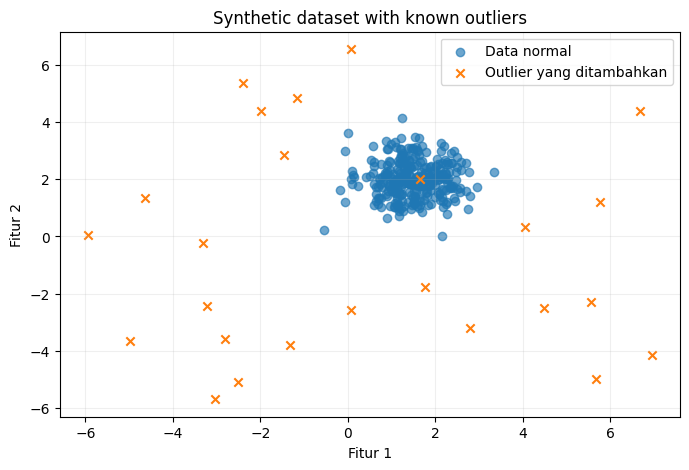

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_normal[:, 0], X_normal[:, 1], label="Data normal", alpha=0.65)
plt.scatter(X_outliers[:, 0], X_outliers[:, 1], label="Outlier yang ditambahkan", marker="x")
plt.title("Synthetic dataset with known outliers")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 11.2 Memahami Isolation Forest

Isolation Forest mendeteksi anomali dengan berulang kali membagi fitur secara acak. Titik yang dapat diisolasi dengan lebih sedikit pembagian cenderung memperoleh skor lebih anomali. Metode ini dapat menjadi pilihan awal untuk deteksi umum, termasuk pada dataset dengan banyak fitur.

Parameter penting:
- `n_estimators`: jumlah pohon isolasi.
- `contamination`: perkiraan proporsi anomali; nilai ini memengaruhi ambang prediksi.
- `random_state`: membantu membuat hasil eksperimen dapat direproduksi.

In [ ]:
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=len(X_outliers) / len(X_all),
    random_state=RANDOM_STATE
)
iso_pred_raw = iso_forest.fit_predict(X_all)
iso_pred = (iso_pred_raw == -1).astype(int)  # 1 = detected outlier
iso_anomaly_score = -iso_forest.decision_function(X_all)

print("Outlier yang terdeteksi:", int(iso_pred.sum()))
print("Precision:", round(precision_score(y_true, iso_pred), 3))
print("Recall:", round(recall_score(y_true, iso_pred), 3))
print("F1-score:", round(f1_score(y_true, iso_pred), 3))

Outlier yang terdeteksi: 25
Precision: 0.96
Recall: 0.96
F1-score: 0.96


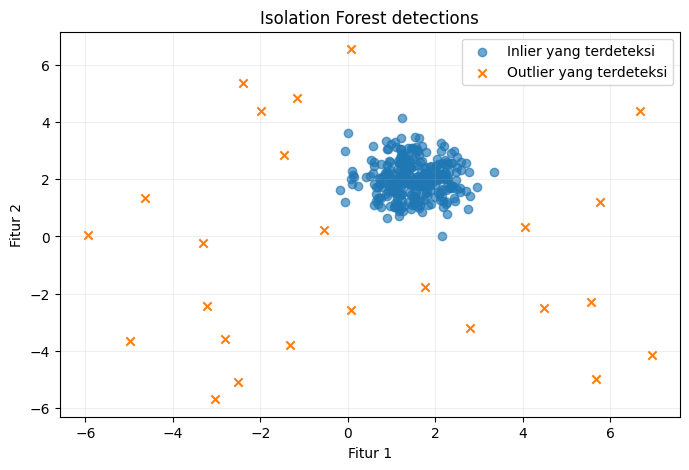

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_all[iso_pred == 0, 0], X_all[iso_pred == 0, 1],
            label="Inlier yang terdeteksi", alpha=0.65)
plt.scatter(X_all[iso_pred == 1, 0], X_all[iso_pred == 1, 1],
            label="Outlier yang terdeteksi", marker="x")
plt.title("Isolation Forest detections")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Menafsirkan hasil

Keluaran detektor bergantung pada proporsi anomali dan distribusi data. Bandingkan label yang terdeteksi dengan label sintetis yang diketahui, jangan berasumsi bahwa setiap outlier buatan pasti akan terdeteksi. Observasi normal yang berada dekat batas kelompok juga dapat ditandai sebagai anomali.

## 11.3 One-Class SVM untuk novelty detection

One-Class SVM mempelajari batas di sekitar contoh pelatihan yang diasumsikan normal. Metode ini berguna ketika data pelatihan hanya berisi contoh normal, lalu model digunakan untuk menilai observasi yang datang pada masa mendatang. Scaling fitur penting karena batas SVM bergantung pada jarak dan besar fitur.

Dalam contoh ini, model **hanya dilatih menggunakan sampel normal**, kemudian diuji pada campuran titik normal dan titik baru yang sengaja dibuat tidak biasa.

In [ ]:
X_train_normal, _ = make_blobs(
    n_samples=300, centers=[[0, 0]], cluster_std=0.55,
    random_state=RANDOM_STATE
)
X_test_normal, _ = make_blobs(
    n_samples=100, centers=[[0, 0]], cluster_std=0.55,
    random_state=RANDOM_STATE + 1
)
rng_novel = np.random.default_rng(RANDOM_STATE + 2)
X_novel = rng_novel.uniform(low=-5, high=6, size=(20, 2))
X_test_mix = np.vstack([X_test_normal, X_novel])
y_test_mix = np.r_[np.zeros(len(X_test_normal), dtype=int),
                   np.ones(len(X_novel), dtype=int)]

print("Data latih hanya berisi data normal:", X_train_normal.shape)
print("Data uji campuran:", X_test_mix.shape)

Data latih hanya berisi data normal: (300, 2)
Data uji campuran: (120, 2)


In [ ]:
ocsvm = make_pipeline(
    StandardScaler(),
    OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
)
ocsvm.fit(X_train_normal)  # Do not include novelty samples in training
ocsvm_pred_raw = ocsvm.predict(X_test_mix)
ocsvm_pred = (ocsvm_pred_raw == -1).astype(int)
ocsvm_anomaly_score = -ocsvm.decision_function(X_test_mix)

print(classification_report(
    y_test_mix, ocsvm_pred,
    target_names=["Inlier", "Novelty"],
    zero_division=0
))

              precision    recall  f1-score   support

      Inlier       0.96      0.96      0.96       100
     Novelty       0.80      0.80      0.80        20

    accuracy                           0.93       120
   macro avg       0.88      0.88      0.88       120
weighted avg       0.93      0.93      0.93       120



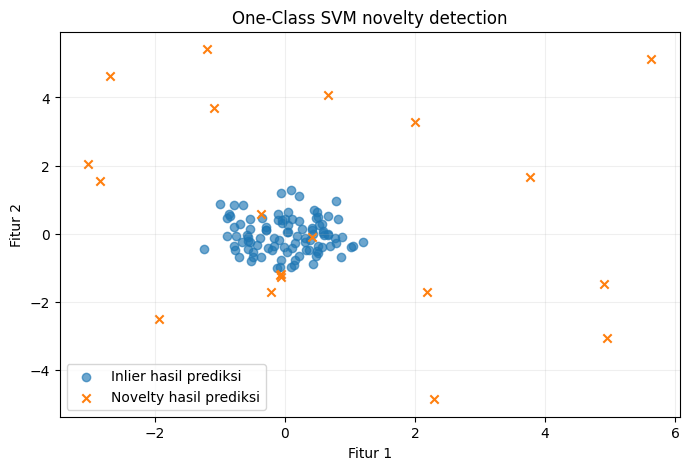

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test_mix[ocsvm_pred == 0, 0], X_test_mix[ocsvm_pred == 0, 1],
            label="Inlier hasil prediksi", alpha=0.65)
plt.scatter(X_test_mix[ocsvm_pred == 1, 0], X_test_mix[ocsvm_pred == 1, 1],
            label="Novelty hasil prediksi", marker="x")
plt.title("One-Class SVM novelty detection")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Perbedaan outlier detection dan novelty detection

Perbedaannya terletak pada kondisi data pelatihan dan tujuan penggunaan:
- **Outlier detection:** data pelatihan itu sendiri mungkin mengandung pencilan; tugasnya adalah menemukan pencilan di dalam dataset tersebut.
- **Novelty detection:** data pelatihan dianggap bersih/normal, lalu observasi baru diperiksa terhadap pola normal yang telah dipelajari.

One-Class SVM sering digunakan untuk skenario kedua. Pada alur kerja ini, jangan memasukkan contoh novelty yang telah diketahui ke dalam data pelatihan yang seharusnya hanya memuat data normal.

## 11.4 Mendeteksi pencilan dengan Local Outlier Factor (LOF)

LOF membandingkan kepadatan lokal suatu titik dengan kepadatan titik-titik tetangganya. Titik yang berada di wilayah jauh lebih renggang dibandingkan lingkungannya mungkin ditandai sebagai anomali. Perspektif lokal ini berguna ketika dataset memiliki kelompok dengan kepadatan yang berbeda.

Dengan `novelty=False` (pengaturan bawaan), gunakan `fit_predict` untuk mendeteksi pencilan pada dataset yang digunakan saat fitting. Untuk memprediksi sampel baru yang belum pernah dilihat, buat LOF dengan `novelty=True` dan gunakan alur prediksi yang sesuai.

In [ ]:
# Buat data dengan cluster berkepadatan berbeda dan noise yang tersebar.
X_dense, _ = make_blobs(
    n_samples=180, centers=[[0, 0]], cluster_std=0.35,
    random_state=RANDOM_STATE
)
X_wide, _ = make_blobs(
    n_samples=120, centers=[[4, 4]], cluster_std=0.9,
    random_state=RANDOM_STATE + 1
)
rng_lof = np.random.default_rng(RANDOM_STATE + 2)
X_noise = rng_lof.uniform(low=-3, high=8, size=(25, 2))
X_lof = np.vstack([X_dense, X_wide, X_noise])
y_lof_true = np.r_[np.zeros(len(X_dense) + len(X_wide), dtype=int),
                   np.ones(len(X_noise), dtype=int)]

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.07)
lof_pred_raw = lof.fit_predict(X_lof)
lof_pred = (lof_pred_raw == -1).astype(int)
lof_anomaly_score = -lof.negative_outlier_factor_

print("Outlier yang ditandai LOF:", int(lof_pred.sum()))
print("Precision:", round(precision_score(y_lof_true, lof_pred), 3))
print("Recall:", round(recall_score(y_lof_true, lof_pred), 3))

Outlier yang ditandai LOF: 23
Precision: 0.783
Recall: 0.72


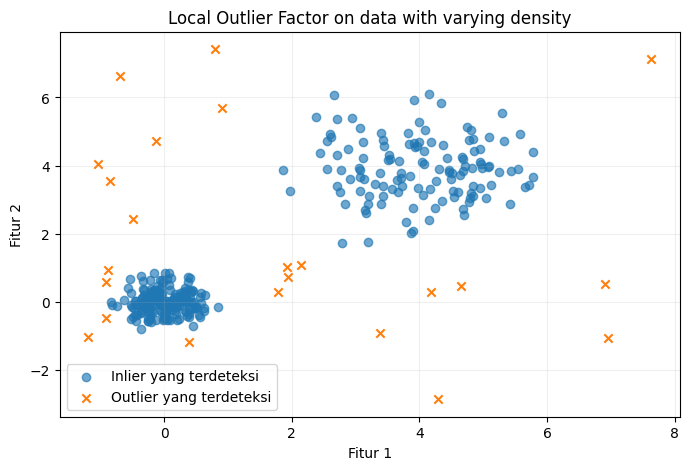

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_lof[lof_pred == 0, 0], X_lof[lof_pred == 0, 1],
            label="Inlier yang terdeteksi", alpha=0.65)
plt.scatter(X_lof[lof_pred == 1, 0], X_lof[lof_pred == 1, 1],
            label="Outlier yang terdeteksi", marker="x")
plt.title("Local Outlier Factor on data with varying density")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Kapan LOF berguna?

LOF berfokus pada perbedaan kepadatan lokal, bukan hanya jarak dari satu pusat global. Hasilnya dapat sangat dipengaruhi oleh `n_neighbors` dan `contamination`. Karena itu, cobalah beberapa nilai parameter, alih-alih menganggap satu pengaturan pasti paling benar.

## 11.5 Mengevaluasi model deteksi pencilan

Jika label sebenarnya diketahui, detektor anomali dapat dibandingkan menggunakan confusion matrix, precision, recall, F1-score, dan ROC-AUC. Pada dataset nyata tanpa label, metrik tersebut tidak dapat dihitung langsung tanpa label terverifikasi atau strategi evaluasi yang sesuai.

Untuk metode di bawah, `1` berarti outlier. Skor mentah diubah agar **nilai yang lebih besar menunjukkan tingkat anomali yang lebih tinggi**, sesuai kebutuhan perhitungan ROC-AUC.

In [ ]:
# Evaluasi Isolation Forest pada dataset pertama (label sintetis diketahui).
print("Isolation Forest")
print(classification_report(
    y_true, iso_pred, target_names=["Inlier", "Outlier"], zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_true, iso_anomaly_score), 3))

Isolation Forest
              precision    recall  f1-score   support

      Inlier       1.00      1.00      1.00       300
     Outlier       0.96      0.96      0.96        25

    accuracy                           0.99       325
   macro avg       0.98      0.98      0.98       325
weighted avg       0.99      0.99      0.99       325

ROC-AUC: 0.961


In [ ]:
cm = confusion_matrix(y_true, iso_pred, labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["True inlier", "True outlier"],
    columns=["Inlier hasil prediksi", "Predicted outlier"]
)
cm_df

,Inlier hasil prediksi,Predicted outlier
True inlier,299,1
True outlier,1,24


In [ ]:
# Bandingkan detektor pada dataset berlabel yang sama.
# LOF digunakan dalam mode deteksi outlier pada X_all.
lof_eval = LocalOutlierFactor(n_neighbors=20, contamination=len(X_outliers) / len(X_all))
lof_eval_pred = (lof_eval.fit_predict(X_all) == -1).astype(int)
lof_eval_score = -lof_eval.negative_outlier_factor_

comparison_rows = []
for name, yhat, score in [
    ("Isolation Forest", iso_pred, iso_anomaly_score),
    ("Local Outlier Factor", lof_eval_pred, lof_eval_score),
]:
    comparison_rows.append({
        "Model": name,
        "Precision": precision_score(y_true, yhat, zero_division=0),
        "Recall": recall_score(y_true, yhat, zero_division=0),
        "F1-score": f1_score(y_true, yhat, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score),
        "Predicted outliers": int(yhat.sum())
    })

pd.DataFrame(comparison_rows).round(3)

,Model,Precision,Recall,F1-score,ROC-AUC,Predicted outliers
0,Isolation Forest,0.96,0.96,0.96,0.961,25
1,Local Outlier Factor,0.96,0.96,0.96,0.961,25


### Hal yang perlu diperhatikan saat evaluasi

- **Precision** menjawab: dari observasi yang ditandai sebagai anomali, berapa banyak yang benar-benar anomali?
- **Recall** menjawab: dari seluruh anomali sebenarnya, berapa banyak yang berhasil dikenali?
- **F1-score** menyeimbangkan precision dan recall.
- **ROC-AUC** menilai kemampuan skor anomali menempatkan anomali di atas titik normal.

Jika anomali sangat jarang, akurasi saja bisa menyesatkan: model yang memprediksi semua titik sebagai normal mungkin tetap memperoleh akurasi tinggi.

## 11.6 Menangani outlier yang terdeteksi

Mendeteksi pencilan dan menghapusnya adalah dua keputusan yang berbeda. Nilai yang tidak biasa bisa berupa kesalahan input, pembacaan sensor yang rusak, kejadian langka yang valid, atau peringatan yang berharga. Selalu selidiki dan gunakan pengetahuan domain sebelum menghapus data.

Contoh berikut menunjukkan penyaringan data sebagai salah satu pilihan, bukan sebagai aturan yang berlaku untuk semua kasus.

In [ ]:
# Latih Isolation Forest dan tandai observasi yang dianggap anomali.
cleanup_model = IsolationForest(
    contamination=0.08, random_state=RANDOM_STATE
)
cleanup_pred = cleanup_model.fit_predict(X_all)
keep_mask = cleanup_pred == 1
X_filtered = X_all[keep_mask]

print("Jumlah baris sebelum ditinjau:", len(X_all))
print("Baris yang ditandai untuk ditinjau:", int((~keep_mask).sum()))
print("Jumlah baris setelah demonstrasi penyaringan:", len(X_filtered))

Jumlah baris sebelum ditinjau: 325
Baris yang ditandai untuk ditinjau: 26
Jumlah baris setelah demonstrasi penyaringan: 299


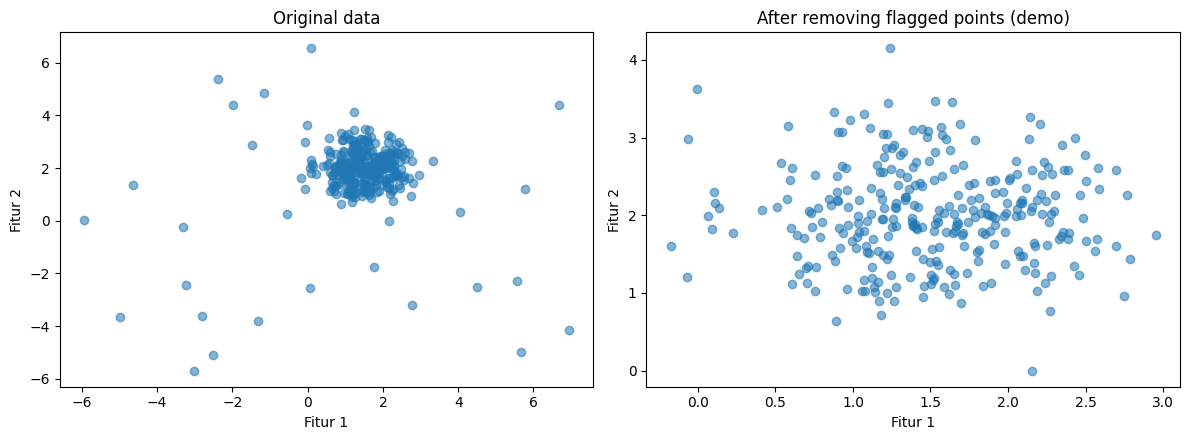

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_all[:, 0], X_all[:, 1], alpha=0.55)
axes[0].set_title("Original data")
axes[0].set_xlabel("Fitur 1")
axes[0].set_ylabel("Fitur 2")

axes[1].scatter(X_filtered[:, 0], X_filtered[:, 1], alpha=0.55)
axes[1].set_title("After removing flagged points (demo)")
axes[1].set_xlabel("Fitur 1")
axes[1].set_ylabel("Fitur 2")

plt.tight_layout()
plt.show()

Pilihan tindakan setelah anomali ditemukan antara lain:

1. Perbaiki kesalahan data yang sudah terkonfirmasi pada sumbernya.
2. Pertahankan contoh langka tetapi valid, terutama jika penting bagi aplikasi.
3. Tinjau catatan yang ditandai bersama ahli bidang terkait.
4. Pertimbangkan model yang robust atau penanda anomali khusus daripada menghapus catatan.
5. Pantau tingkat anomali dari waktu ke waktu untuk mendeteksi perubahan dalam alur data.

## 11.7 Memilih teknik deteksi yang sesuai

Tidak ada satu detektor yang paling baik untuk semua dataset. Pemilihan bergantung pada ukuran data, jumlah fitur, struktur kelompok, asumsi apakah data pelatihan normal, serta kebutuhan kecepatan inferensi dan interpretabilitas.

In [ ]:
selection_guide = pd.DataFrame({
    "Method": ["Isolation Forest", "Local Outlier Factor (LOF)", "One-Class SVM"],
    "Normal tipikal fit": [
        "General-purpose; large or high-dimensional data",
        "Local anomalies and varying local densities",
        "Novelty detection with normal-only training data"
    ],
    "Key parameters": [
        "n_estimators, contamination",
        "n_neighbors, contamination",
        "kernel, gamma, nu"
    ],
    "Important limitation": [
        "May miss anomalies that are not easy to isolate",
        "Default mode is intended for the fitted dataset",
        "Sensitive to scaling and can be expensive on large datasets"
    ]
})
selection_guide

,Method,Normal tipikal fit,Key parameters,Important limitation
0,Isolation Forest,General-purpose; large or high-dimensional data,"n_estimators, contamination",May miss anomalies that are not easy to isolate
1,Local Outlier Factor (LOF),Local anomalies and varying local densities,"n_neighbors, contamination",Default mode is intended for the fitted dataset
2,One-Class SVM,Novelty detection with normal-only training data,"kernel, gamma, nu",Sensitive to scaling and can be expensive on l...


## Latihan praktis

Selesaikan latihan berikut dengan menjalankan kode, menafsirkan metrik, dan mengubah setidaknya satu parameter. Data dibuat secara lokal agar notebook mudah direproduksi.

### Latihan 1: Menerapkan Isolation Forest pada data operasional simulasi

Anggap kelompok padat sebagai perilaku peralatan yang biasa, sedangkan titik yang tersebar merata merupakan potensi gangguan. Evaluasi detektor terhadap label yang dibuat bersama dataset.

In [ ]:
X_ok, _ = make_blobs(
    n_samples=400, centers=[[0, 0]], cluster_std=0.7,
    random_state=RANDOM_STATE
)
rng_ex1 = np.random.default_rng(RANDOM_STATE + 10)
X_fault = rng_ex1.uniform(-7, 7, size=(35, 2))
X_ex1 = np.vstack([X_ok, X_fault])
y_ex1 = np.r_[np.zeros(len(X_ok), dtype=int),
              np.ones(len(X_fault), dtype=int)]

ex1_model = make_pipeline(
    StandardScaler(),
    IsolationForest(contamination=len(X_fault) / len(X_ex1),
                    random_state=RANDOM_STATE)
)
# Konvensi prediksi pipeline tetap 1=inlier dan -1=outlier.
ex1_pred = (ex1_model.fit_predict(X_ex1) == -1).astype(int)
print(classification_report(
    y_ex1, ex1_pred, target_names=["Normal", "Anomaly"], zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       400
     Anomaly       0.89      0.89      0.89        35

    accuracy                           0.98       435
   macro avg       0.94      0.94      0.94       435
weighted avg       0.98      0.98      0.98       435



**Refleksi:** ubah `contamination` menjadi `0.05`. Apakah jumlah catatan yang ditandai berubah? Apa kompromi antara menemukan lebih banyak anomali dan menghasilkan lebih banyak alarm palsu?

### Latihan 2: Menggunakan LOF pada dataset yang menyerupai lalu lintas jaringan

Simulasikan beberapa kelompok lalu lintas dan sejumlah titik tak biasa yang tersebar. Pada jaringan nyata, fitur dapat mewakili durasi koneksi, jumlah paket, atau percobaan login gagal; pada latihan ini, semua fitur numerik dibuat secara sintetis.

In [ ]:
X_net_a, _ = make_blobs(
    n_samples=220, centers=[[-1, 0], [2.5, 2.0]],
    cluster_std=[0.45, 0.8], random_state=RANDOM_STATE
)
rng_ex2 = np.random.default_rng(RANDOM_STATE + 11)
X_net_noise = rng_ex2.uniform(-4, 5, size=(30, 2))
X_net = np.vstack([X_net_a, X_net_noise])
y_net = np.r_[np.zeros(len(X_net_a), dtype=int),
              np.ones(len(X_net_noise), dtype=int)]

net_scaler = StandardScaler()
X_net_scaled = net_scaler.fit_transform(X_net)
ex2_lof = LocalOutlierFactor(n_neighbors=25, contamination=0.10)
ex2_pred = (ex2_lof.fit_predict(X_net_scaled) == -1).astype(int)

print("Anomali yang diprediksi:", int(ex2_pred.sum()))
print(classification_report(
    y_net, ex2_pred, target_names=["Normal tipikal", "Potential intrusion"],
    zero_division=0
))

Anomali yang diprediksi: 25
                     precision    recall  f1-score   support

     Normal tipikal       0.95      0.97      0.96       220
Potential intrusion       0.76      0.63      0.69        30

           accuracy                           0.93       250
          macro avg       0.86      0.80      0.83       250
       weighted avg       0.93      0.93      0.93       250



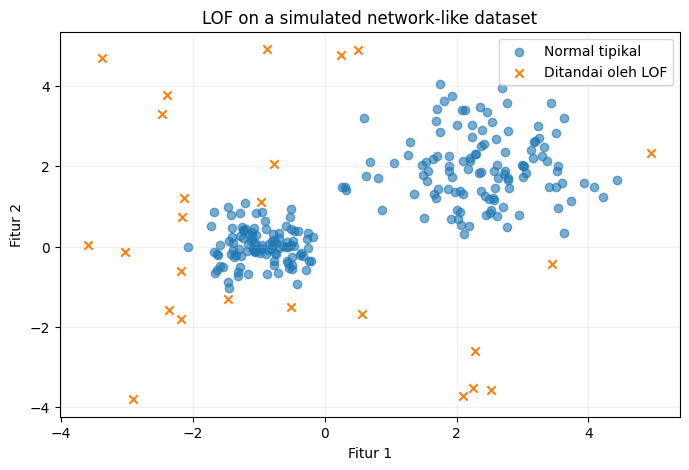

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_net[ex2_pred == 0, 0], X_net[ex2_pred == 0, 1],
            label="Normal tipikal", alpha=0.6)
plt.scatter(X_net[ex2_pred == 1, 0], X_net[ex2_pred == 1, 1],
            label="Ditandai oleh LOF", marker="x")
plt.title("LOF on a simulated network-like dataset")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Refleksi:** ubah `n_neighbors` dari 25 menjadi 10, lalu 40. Bagaimana perubahan ukuran lingkungan lokal memengaruhi deteksi anomali?

### Latihan 3: One-Class SVM untuk data sensor manufaktur

Latih model hanya dengan pembacaan normal dari peralatan. Setelah itu, gunakan detektor novelty untuk mengenali pembacaan yang tidak biasa. Ini menggambarkan skenario novelty detection: contoh abnormal pada data uji tidak boleh dimasukkan ke data pelatihan.

In [ ]:
X_factory_train, _ = make_blobs(
    n_samples=350, centers=[[1.0, 1.0]], cluster_std=0.5,
    random_state=RANDOM_STATE
)
X_factory_normal, _ = make_blobs(
    n_samples=100, centers=[[1.0, 1.0]], cluster_std=0.5,
    random_state=RANDOM_STATE + 12
)
rng_ex3 = np.random.default_rng(RANDOM_STATE + 13)
X_factory_novel = rng_ex3.uniform(-4, 6, size=(25, 2))
X_factory_test = np.vstack([X_factory_normal, X_factory_novel])
y_factory_test = np.r_[np.zeros(len(X_factory_normal), dtype=int),
                       np.ones(len(X_factory_novel), dtype=int)]

factory_model = make_pipeline(
    StandardScaler(),
    OneClassSVM(kernel="rbf", gamma="scale", nu=0.06)
)
factory_model.fit(X_factory_train)
factory_pred = (factory_model.predict(X_factory_test) == -1).astype(int)

print(classification_report(
    y_factory_test, factory_pred,
    target_names=["Normal operation", "Novel reading"],
    zero_division=0
))

                  precision    recall  f1-score   support

Normal operation       0.98      0.95      0.96       100
   Novel reading       0.82      0.92      0.87        25

        accuracy                           0.94       125
       macro avg       0.90      0.94      0.92       125
    weighted avg       0.95      0.94      0.95       125



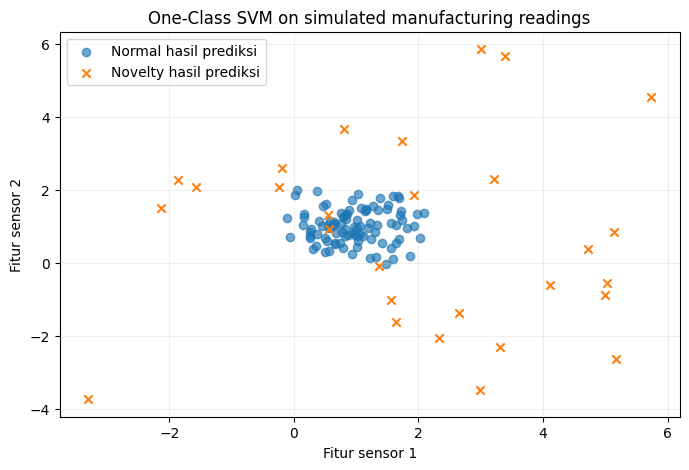

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_factory_test[factory_pred == 0, 0],
            X_factory_test[factory_pred == 0, 1],
            label="Normal hasil prediksi", alpha=0.65)
plt.scatter(X_factory_test[factory_pred == 1, 0],
            X_factory_test[factory_pred == 1, 1],
            label="Novelty hasil prediksi", marker="x")
plt.title("One-Class SVM on simulated manufacturing readings")
plt.xlabel("Fitur sensor 1")
plt.ylabel("Fitur sensor 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Ringkasan dan poin penting

- Outlier detection mencari observasi tidak biasa di dalam dataset, sedangkan novelty detection memeriksa observasi baru berdasarkan data pelatihan yang hanya dianggap normal.
- **Isolation Forest** mengisolasi anomali melalui pembagian fitur acak dan dapat menjadi baseline serbaguna.
- **One-Class SVM** mempelajari batas di sekitar observasi normal dan sensitif terhadap scaling fitur.
- **LOF** membandingkan kepadatan lokal dan dapat menemukan titik yang berbeda dari tetangganya.
- Gunakan precision, recall, F1-score, confusion matrix, dan ROC-AUC jika label terverifikasi tersedia. Tafsirkan hasil dengan mempertimbangkan jumlah anomali serta biaya alarm palsu dan anomali yang terlewat.
- Anggap penandaan model sebagai dasar untuk ditinjau, bukan perintah otomatis untuk menghapus data.

**Kesesuaian sumber:** notebook ini mencakup tujuh kelompok topik di Bab 11 *scikit-learn Cookbook, Third Edition*, dengan penjelasan dan contoh sintetis yang disusun tersendiri.